   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]
Dataset Shape: (1000, 16)
Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1000 non-null   int64
 1   Gender                   1000 non-null   object
 2   Cholesterol     

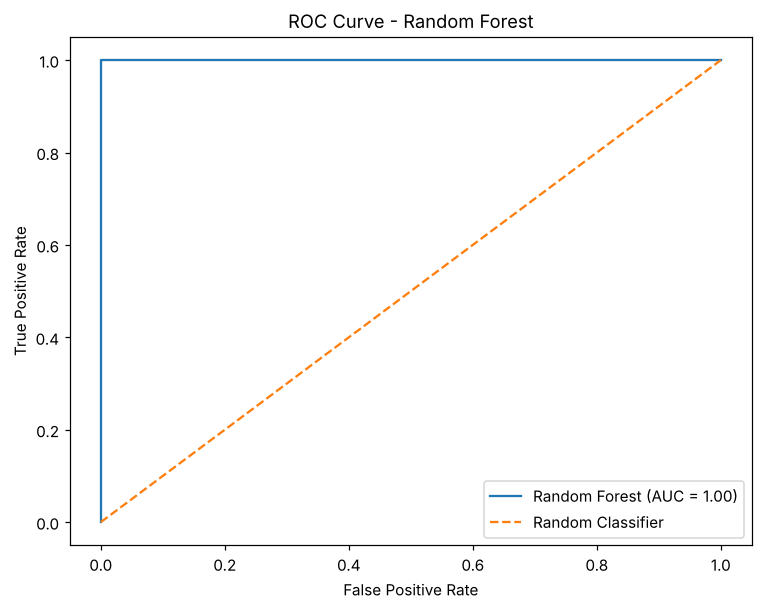

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Load the dataset

df = pd.read_csv("heart_disease_dataset.csv")

# Display first 5 rows
df.head()

# Display number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names

print(df.columns)

# Display data types

df.info()

# Check missing values

print(df.isnull().sum())

# Check target class distribution

print(df["Heart Disease"].value_counts())

# X contains input features
# y contains the target variable

X = df.drop("Heart Disease", axis=1)

y = df["Heart Disease"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Identify numerical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

# Preprocessing for numerical and categorical features

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Create Random Forest classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and Random Forest model

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_model)
    ]
)

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Train the model

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

# Predict on training data

y_train_pred = model.predict(X_train)

# Predict on testing data

y_test_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

# Calculate evaluation metrics

train_accuracy = accuracy_score(y_train, y_train_pred)

test_accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(y_test, y_test_pred)

recall = recall_score(y_test, y_test_pred)

f1 = f1_score(y_test, y_test_pred)

print("Training Accuracy :", round(train_accuracy, 4))
print("Testing Accuracy  :", round(test_accuracy, 4))
print("Precision         :", round(precision, 4))
print("Recall            :", round(recall, 4))
print("F1 Score          :", round(f1, 4))

# Predict probabilities

y_test_proba = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

# Calculate AUC

auc_score = roc_auc_score(y_test, y_test_proba)

print("ROC-AUC Score:", round(auc_score, 4))

# Plot ROC Curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest")

plt.legend()

plt.show()
